Loaded 263 spatial zones.
Shapefile Columns: ['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']


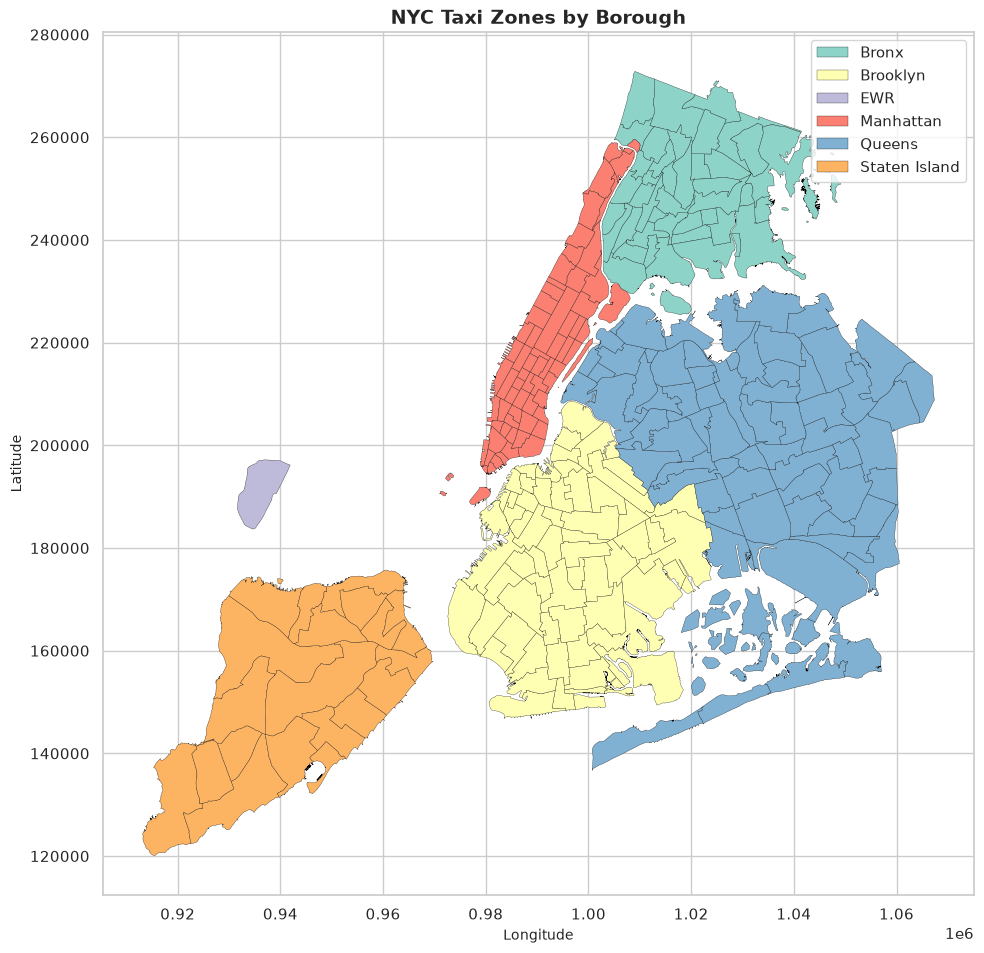

In [15]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load the spatial polygons from the ESRI shapefile bundle
# Ensure all files (shp, shx, dbf, prj) are in your '../data/spatial/' directory
shapefile_path = '../data/spatial/taxi_zones.shp'
gdf_zones = gpd.read_file(shapefile_path)

print(f"Loaded {len(gdf_zones)} spatial zones.")
print("Shapefile Columns:", gdf_zones.columns.tolist())

# 2. (Optional) Load the taxi zone lookup CSV to merge descriptive metadata (Borough, Zone names)
import pandas as pd
df_lookup = pd.read_csv('../data/spatial/taxi_zone_lookup.csv')

# Merge shapefile with lookup table on LocationID
# Note: The shapefile usually stores the ID under 'LocationID' or 'OBJECTID'
if 'LocationID' in gdf_zones.columns:
    gdf_merged = gdf_zones.merge(df_lookup, on='LocationID', how='left')
else:
    # Fallback if the shapefile column is named 'OBJECTID'
    gdf_merged = gdf_zones.merge(df_lookup, left_on='OBJECTID', right_on='LocationID', how='left')

# 3. Plot the spatial polygons
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Plot polygons colored by Borough (or just plain if borough isn't merged)
if 'Borough' in gdf_merged.columns:
    gdf_merged.plot(
        column='Borough', 
        ax=ax, 
        legend=True, 
        edgecolor='black', 
        linewidth=0.2, 
        cmap='Set3',
        missing_kwds={'color': 'lightgrey'}
    )
    plt.title('NYC Taxi Zones by Borough', fontsize=14, fontweight='bold')
else:
    gdf_merged.plot(ax=ax, color='lightblue', edgecolor='black', linewidth=0.2)
    plt.title('NYC Taxi Zone Polygons', fontsize=14, fontweight='bold')

plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/figures/nyc_taxi_zones_map.png', dpi=300)
plt.show()

In [10]:
import duckdb
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})

print("=" * 70)
print("SPATIAL EDA & DEMAND AGGREGATION PIPELINE")
print("=" * 70)

# 1. Connect to DuckDB and aggregate trip counts by Pickup Zone (PULocationID)
con = duckdb.connect(database=':memory:')

spatial_agg_query = """
SELECT 
    PULocationID AS LocationID,
    COUNT(*) AS pickup_trip_count,
    ROUND(AVG(trip_distance), 2) AS avg_trip_distance,
    ROUND(AVG(fare_amount), 2) AS avg_fare_amount
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE PULocationID BETWEEN 1 AND 263
GROUP BY PULocationID;
"""

print("Aggregating trip metrics by pickup zone from clean dataset...")
df_pickup_stats = con.execute(spatial_agg_query).df()
con.close()



SPATIAL EDA & DEMAND AGGREGATION PIPELINE
Aggregating trip metrics by pickup zone from clean dataset...


Loading taxi zone spatial polygons and lookup tables...
Successfully merged spatial polygons with 263 zones.

Aggregating trip volumes by Borough...


C:\Users\pro\AppData\Local\Temp\ipykernel_16036\937237501.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Saved borough volume bar plot to '../reports/figures/spatial_borough_volume.png'!


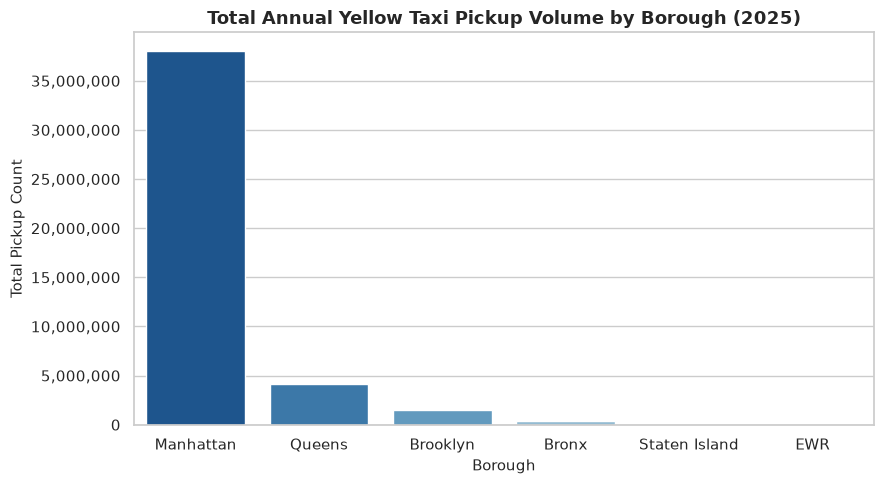

In [11]:
# 2. Load Spatial Shapefile and Lookup Metadata
print("Loading taxi zone spatial polygons and lookup tables...")
gdf_zones = gpd.read_file('../data/spatial/taxi_zones.shp')
df_lookup = pd.read_csv('../data/spatial/taxi_zone_lookup.csv')

# Ensure consistent naming for merge key ('LocationID' or 'OBJECTID')
id_col = 'LocationID' if 'LocationID' in gdf_zones.columns else 'OBJECTID'

# Merge spatial dataframe with aggregated stats and lookup table
gdf_spatial = gdf_zones.merge(df_lookup, left_on=id_col, right_on='LocationID', how='left')
gdf_spatial = gdf_spatial.merge(df_pickup_stats, on='LocationID', how='left')

# Fill missing counts with 0 for unvisited zones
gdf_spatial['pickup_trip_count'] = gdf_spatial['pickup_trip_count'].fillna(0)

print(f"Successfully merged spatial polygons with {len(gdf_spatial)} zones.")


# 5. Generate Borough-Level Aggregation Bar Plot
print("\nAggregating trip volumes by Borough...")
borough_summary = gdf_spatial.groupby('Borough')['pickup_trip_count'].sum().reset_index()
borough_summary = borough_summary.sort_values(by='pickup_trip_count', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=borough_summary, 
    x='Borough', 
    y='pickup_trip_count', 
    palette='Blues_r', 
    ax=ax
)
ax.set_title('Total Annual Yellow Taxi Pickup Volume by Borough (2025)', fontsize=13, fontweight='bold')
ax.set_xlabel('Borough', fontsize=11)
ax.set_ylabel('Total Pickup Count', fontsize=11)
# Format y-axis with commas
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.savefig('../reports/figures/spatial_borough_volume.png', dpi=300)
print("Saved borough volume bar plot to '../reports/figures/spatial_borough_volume.png'!")
plt.show()


Saved log-scale choropleth map to '../reports/figures/spatial_pickup_density_map_log.png'!


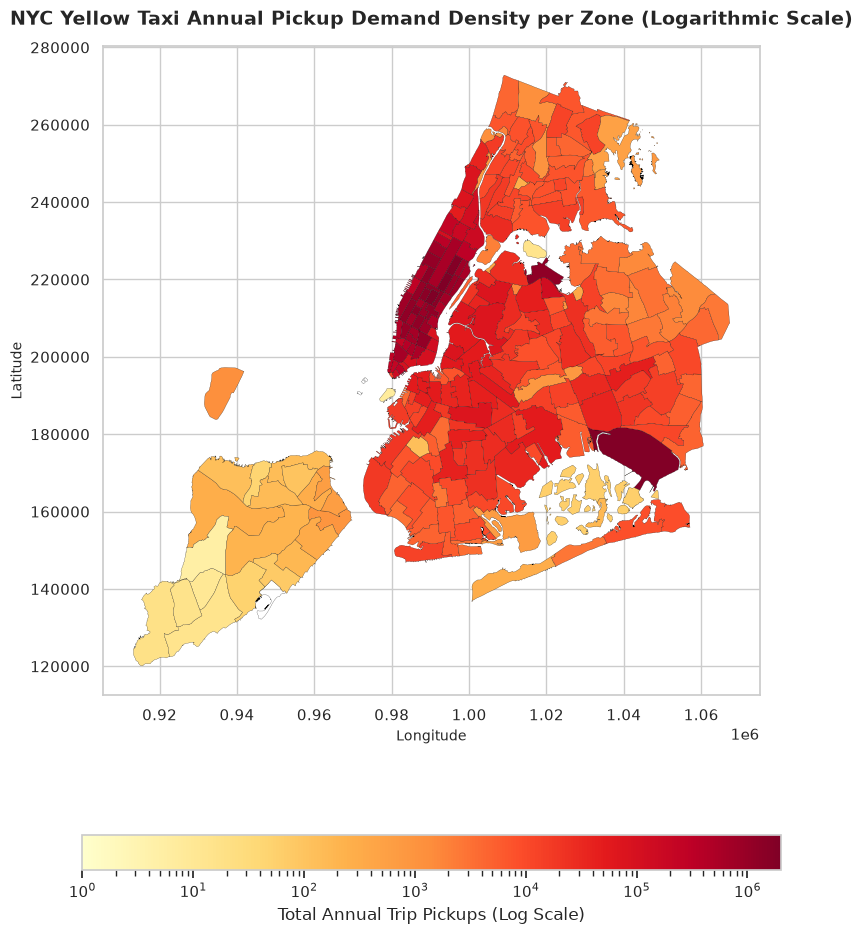

In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

gdf_spatial.plot(
    column='pickup_trip_count',
    ax=ax,
    legend=True,
    legend_kwds={
        'label': 'Total Annual Trip Pickups (Log Scale)', 
        'orientation': 'horizontal', 
        'shrink': 0.6
    },
    cmap='YlOrRd',
    norm=LogNorm(vmin=max(1, gdf_spatial['pickup_trip_count'].min()), vmax=gdf_spatial['pickup_trip_count'].max()),
    edgecolor='black',
    linewidth=0.15,
    missing_kwds={'color': 'lightgrey'}
)

plt.title('NYC Yellow Taxi Annual Pickup Demand Density per Zone (Logarithmic Scale)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/figures/spatial_pickup_density_map_log.png', dpi=300)
print("\nSaved log-scale choropleth map to '../reports/figures/spatial_pickup_density_map_log.png'!")
plt.show()

In [12]:
# 3. Print Top 10 Busiest Pickup Zones
print("\n--- Top 10 Busiest Pickup Zones (2025) ---")
top_pickup_zones = gdf_spatial.sort_values(by='pickup_trip_count', ascending=False)[
    ['Zone', 'Borough', 'pickup_trip_count', 'avg_trip_distance', 'avg_fare_amount']
].head(10)
print(top_pickup_zones.to_string(index=False))


--- Top 10 Busiest Pickup Zones (2025) ---
                        Zone   Borough  pickup_trip_count  avg_trip_distance  avg_fare_amount
       Upper East Side South Manhattan          1994156.0               1.80            13.38
              Midtown Center Manhattan          1942432.0               2.34            17.04
                 JFK Airport    Queens          1876676.0              15.47            63.54
       Upper East Side North Manhattan          1742460.0               2.00            13.89
Penn Station/Madison Sq West Manhattan          1441146.0               2.33            17.15
                Midtown East Manhattan          1409260.0               2.30            16.14
   Times Sq/Theatre District Manhattan          1390476.0               3.03            19.42
         Lincoln Square East Manhattan          1283771.0               2.21            14.72
           LaGuardia Airport    Queens          1223332.0               9.61            45.54
                

In [3]:
import duckdb
import pandas as pd

def analyze_borough_stats(borough_name):
    """
    Computes pickup and drop-off descriptive statistics using memory-efficient
    approximate quantiles for a specific NYC Borough.
    """
    con = duckdb.connect(database=':memory:')
    
    # Configure DuckDB to manage memory better and spill to disk if needed
    con.execute("SET memory_limit='4GB';")
    con.execute("SET threads=2;")
    
    query = f"""
    WITH base_data AS (
        SELECT 
            COALESCE(pu_lookup.Borough, 'Unknown') AS pickup_borough,
            COALESCE(do_lookup.Borough, 'Unknown') AS dropoff_borough,
            t.trip_distance,
            t.fare_amount,
            EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes,
            CASE 
                WHEN EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) > 0 
                THEN (t.trip_distance / (EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) / 3600.0))
                ELSE NULL 
            END AS calculated_speed_mph
        FROM '../data/processed/yellow_tripdata_2025_clean.parquet' t
        LEFT JOIN '../data/spatial/taxi_zone_lookup.csv' pu_lookup ON t.PULocationID = pu_lookup.LocationID
        LEFT JOIN '../data/spatial/taxi_zone_lookup.csv' do_lookup ON t.DOLocationID = do_lookup.LocationID
    ),
    filtered_data AS (
        SELECT 'Pickup' AS spatial_type, trip_distance, fare_amount, trip_duration_minutes, calculated_speed_mph
        FROM base_data WHERE pickup_borough = '{borough_name}'
        
        UNION ALL
        
        SELECT 'Dropoff' AS spatial_type, trip_distance, fare_amount, trip_duration_minutes, calculated_speed_mph
        FROM base_data WHERE dropoff_borough = '{borough_name}'
    )
    SELECT 
        '{borough_name}' AS Borough,
        spatial_type,
        COUNT(*) AS total_trips,
        
        -- Distance Stats
        ROUND(AVG(trip_distance), 2) AS mean_distance,
        ROUND(STDDEV(trip_distance), 2) AS std_distance,
        ROUND(approx_quantile(trip_distance, 0.25), 2) AS q1_distance,
        ROUND(approx_quantile(trip_distance, 0.50), 2) AS median_distance,
        ROUND(approx_quantile(trip_distance, 0.75), 2) AS q3_distance,
        
        -- Fare Stats
        ROUND(AVG(fare_amount), 2) AS mean_fare,
        ROUND(STDDEV(fare_amount), 2) AS std_fare,
        ROUND(approx_quantile(fare_amount, 0.25), 2) AS q1_fare,
        ROUND(approx_quantile(fare_amount, 0.50), 2) AS median_fare,
        ROUND(approx_quantile(fare_amount, 0.75), 2) AS q3_fare,
        
        -- Duration Stats
        ROUND(AVG(trip_duration_minutes), 2) AS mean_duration,
        ROUND(STDDEV(trip_duration_minutes), 2) AS std_duration,
        ROUND(approx_quantile(trip_duration_minutes, 0.25), 2) AS q1_duration,
        ROUND(approx_quantile(trip_duration_minutes, 0.50), 2) AS median_duration,
        ROUND(approx_quantile(trip_duration_minutes, 0.75), 2) AS q3_duration,

        -- Speed Stats
        ROUND(AVG(calculated_speed_mph), 2) AS mean_speed,
        ROUND(STDDEV(calculated_speed_mph), 2) AS std_speed,
        ROUND(approx_quantile(calculated_speed_mph, 0.25), 2) AS q1_speed,
        ROUND(approx_quantile(calculated_speed_mph, 0.50), 2) AS median_speed,
        ROUND(approx_quantile(calculated_speed_mph, 0.75), 2) AS q3_speed
    FROM filtered_data
    GROUP BY spatial_type;
    """
    
    df_result = con.execute(query).df()
    con.close()
    return df_result

In [16]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

def plot_borough_distributions_sampled(borough_name, sample_percentage=10):
    """
    Extracts a random sample of clean trip records for a specific borough 
    using a subquery sample, then plots distribution plots and boxplots.
    """
    con = duckdb.connect(database=':memory:')
    con.execute("SET memory_limit='4GB';")
    con.execute("SET threads=2;")
    
    # Query using a subquery sampling approach to guarantee parser compatibility with JOINs
    query = f"""
    WITH sampled_source AS (
        SELECT * 
        FROM '../data/processed/yellow_tripdata_2025_clean.parquet' 
        USING SAMPLE {sample_percentage}% (BERNOULLI)
    )
    SELECT 
        t.trip_distance,
        t.fare_amount,
        EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes,
        CASE 
            WHEN EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) > 0 
            THEN (t.trip_distance / (EXTRACT(EPOCH FROM (t.tpep_dropoff_datetime - t.tpep_pickup_datetime)) / 3600.0))
            ELSE NULL 
        END AS calculated_speed_mph
    FROM sampled_source t
    LEFT JOIN '../data/spatial/taxi_zone_lookup.csv' pu_lookup ON t.PULocationID = pu_lookup.LocationID
    WHERE COALESCE(pu_lookup.Borough, 'Unknown') = '{borough_name}';
    """
    
    print(f"Fetching a {sample_percentage}% random sample for {borough_name}...")
    df_borough = con.execute(query).df()
    con.close()
    
    if df_borough.empty:
        print(f"No records found for borough: {borough_name}")
        return

    print(f"Loaded {len(df_borough):,} sampled rows. Generating plots...")

    variables = [
        ('trip_distance', 'Trip Distance (Miles)', 50),
        ('fare_amount', 'Fare Amount (USD)', 100),
        ('trip_duration_minutes', 'Trip Duration (Minutes)', 60),
        ('calculated_speed_mph', 'Calculated Speed (MPH)', 60)
    ]
    
    # Create a 4x2 grid of subplots (4 variables x [Distribution Plot, Boxplot])
    fig, axes = plt.subplots(4, 2, figsize=(14, 16))
    
    for i, (col, label, cap_val) in enumerate(variables):
        # Filter out extreme outliers visually for cleaner plots if cap_val is provided
        plot_data = df_borough[df_borough[col] <= cap_val][col].dropna()
        
        # 1. Distribution Plot (Hist + KDE)
        sns.histplot(
            plot_data, 
            kde=True, 
            ax=axes[i, 0], 
            color='steelblue', 
            bins=40, 
            stat='density'
        )
        axes[i, 0].set_title(f'{borough_name}: {label} Distribution', fontsize=11, fontweight='bold')
        axes[i, 0].set_xlabel(label, fontsize=10)
        axes[i, 0].set_ylabel('Density', fontsize=10)
        
        # 2. Box Plot
        sns.boxplot(
            x=plot_data, 
            ax=axes[i, 1], 
            color='lightseagreen', 
            fliersize=1
        )
        axes[i, 1].set_title(f'{borough_name}: {label} Boxplot (Capped)', fontsize=11, fontweight='bold')
        axes[i, 1].set_xlabel(label, fontsize=10)
        axes[i, 1].set_ylabel('', fontsize=10)

    plt.suptitle(f'Exploratory Data Analysis: Variable Distributions for {borough_name} (2025)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    filename = f'../reports/figures/{borough_name.lower()}_variables_distribution.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Saved distribution plots for {borough_name} to '{filename}'!")
    plt.show()

Processing borough: Manhattan...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
Manhattan       Pickup     38034750           2.50          2.76         1.02             1.67         2.84      16.38     58.22     9.30        13.28    19.72          14.73         10.43         7.77            12.34        18.87        9.82       4.92      6.70          8.91     11.73
Manhattan      Dropoff     38352036           2.74          3.35         1.02             1.68         2.90      17.17     58.01     9.27        13.43    20.01          15.36         11.76         7.81            12.45        19.20       10.02       5.21      6.73          8.95     11.90
Fetching a 10% random sample for Manhattan...
Loaded 3,800,125 sampled rows. Generating plots...
Saved distribution plots for Manhatt

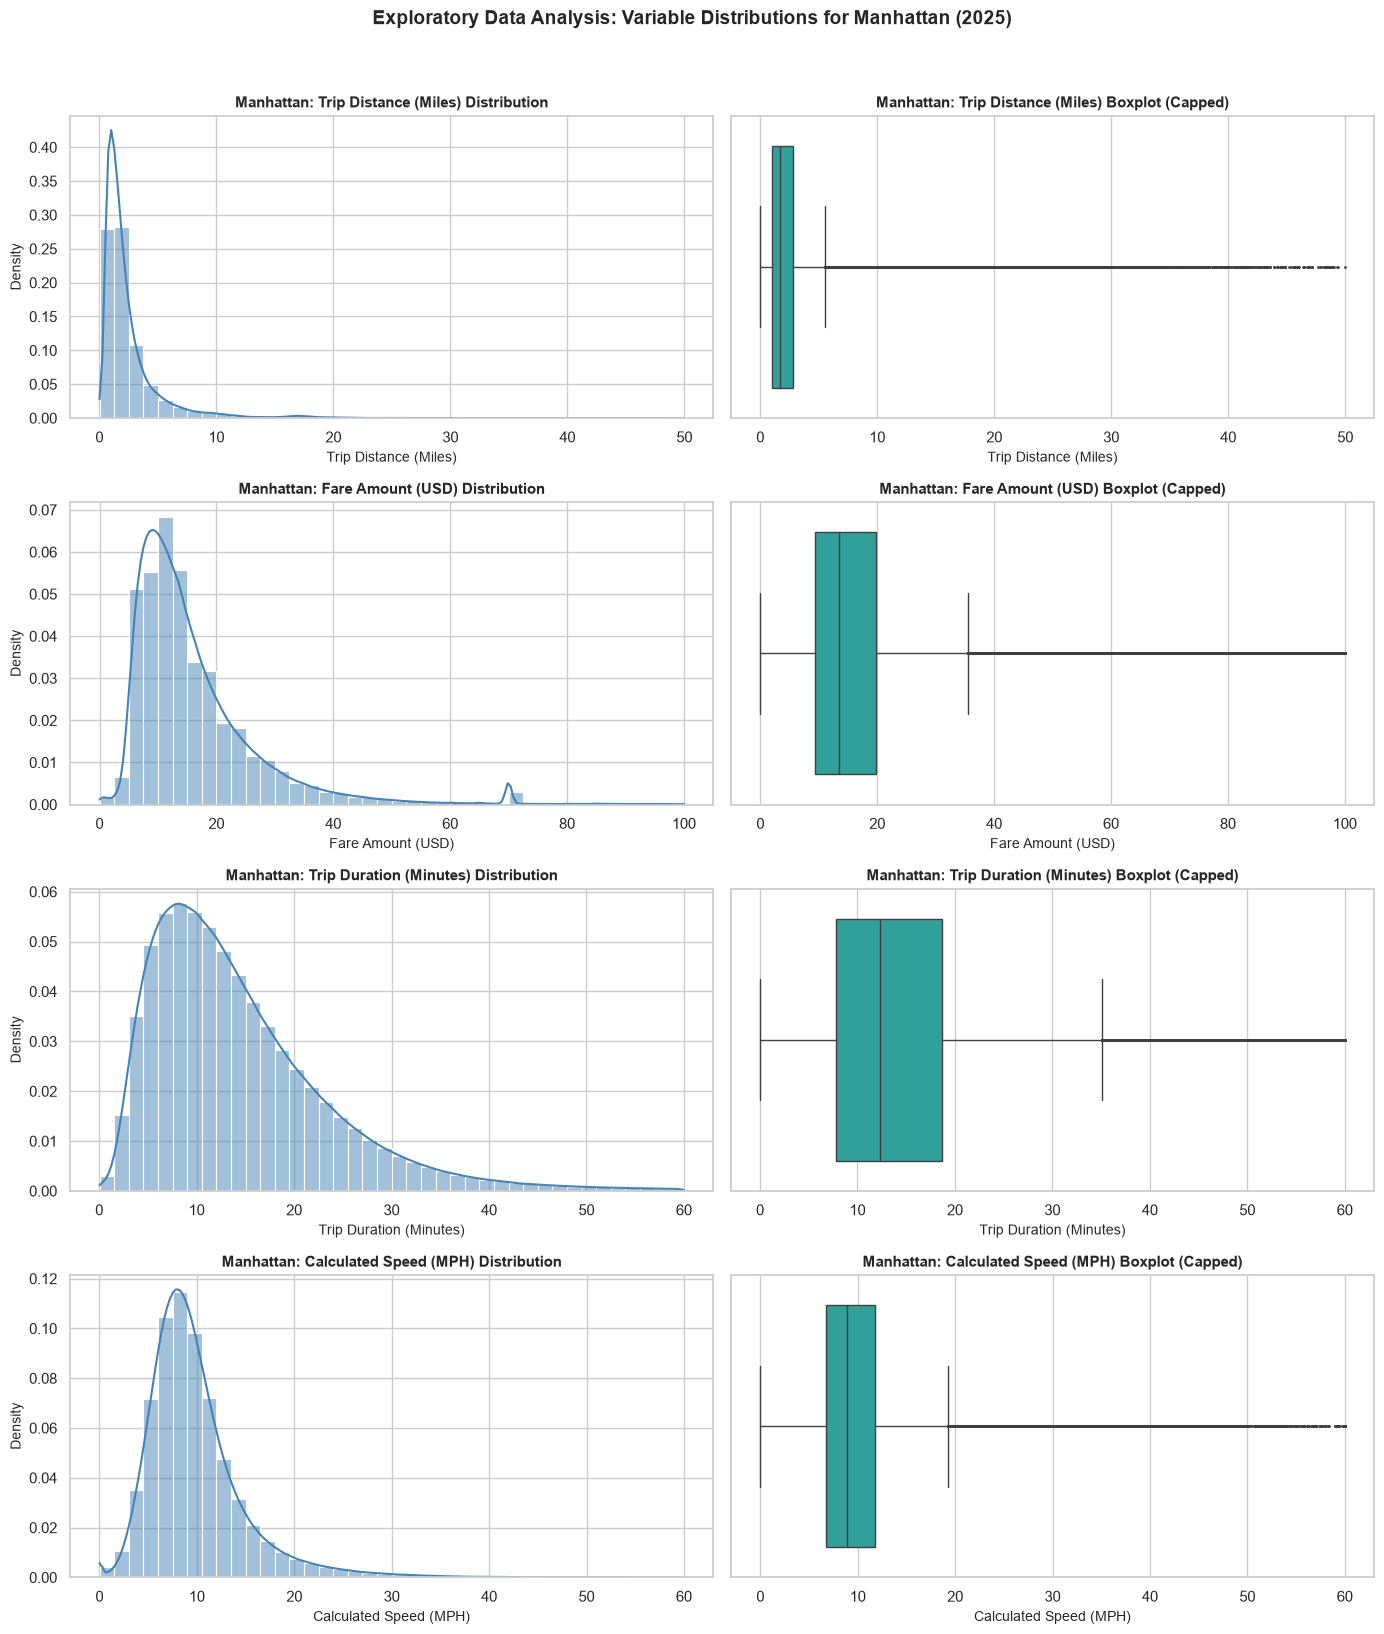

In [17]:
print("Processing borough: Manhattan...")
df_b = analyze_borough_stats('Manhattan')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('Manhattan', sample_percentage=10)

Processing borough: Queens...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
 Queens       Pickup      4165160          11.51          6.54         7.36            10.30        16.97      50.33    452.60    33.20        46.52     70.0          35.26         20.36        20.11            31.97        47.14       20.85       8.49     14.61         19.76     26.04
 Queens      Dropoff      2434066           8.52          5.42         4.15             8.11        11.56      39.08    591.77    22.02        36.11     51.3          28.18         18.99        15.32            23.92        36.41       19.32       8.61     12.95         18.00     24.44
Fetching a 100% random sample for Queens...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 4,165,160 sampled rows. Generating plots...
Saved distribution plots for Queens to '../reports/figures/queens_variables_distribution.png'!


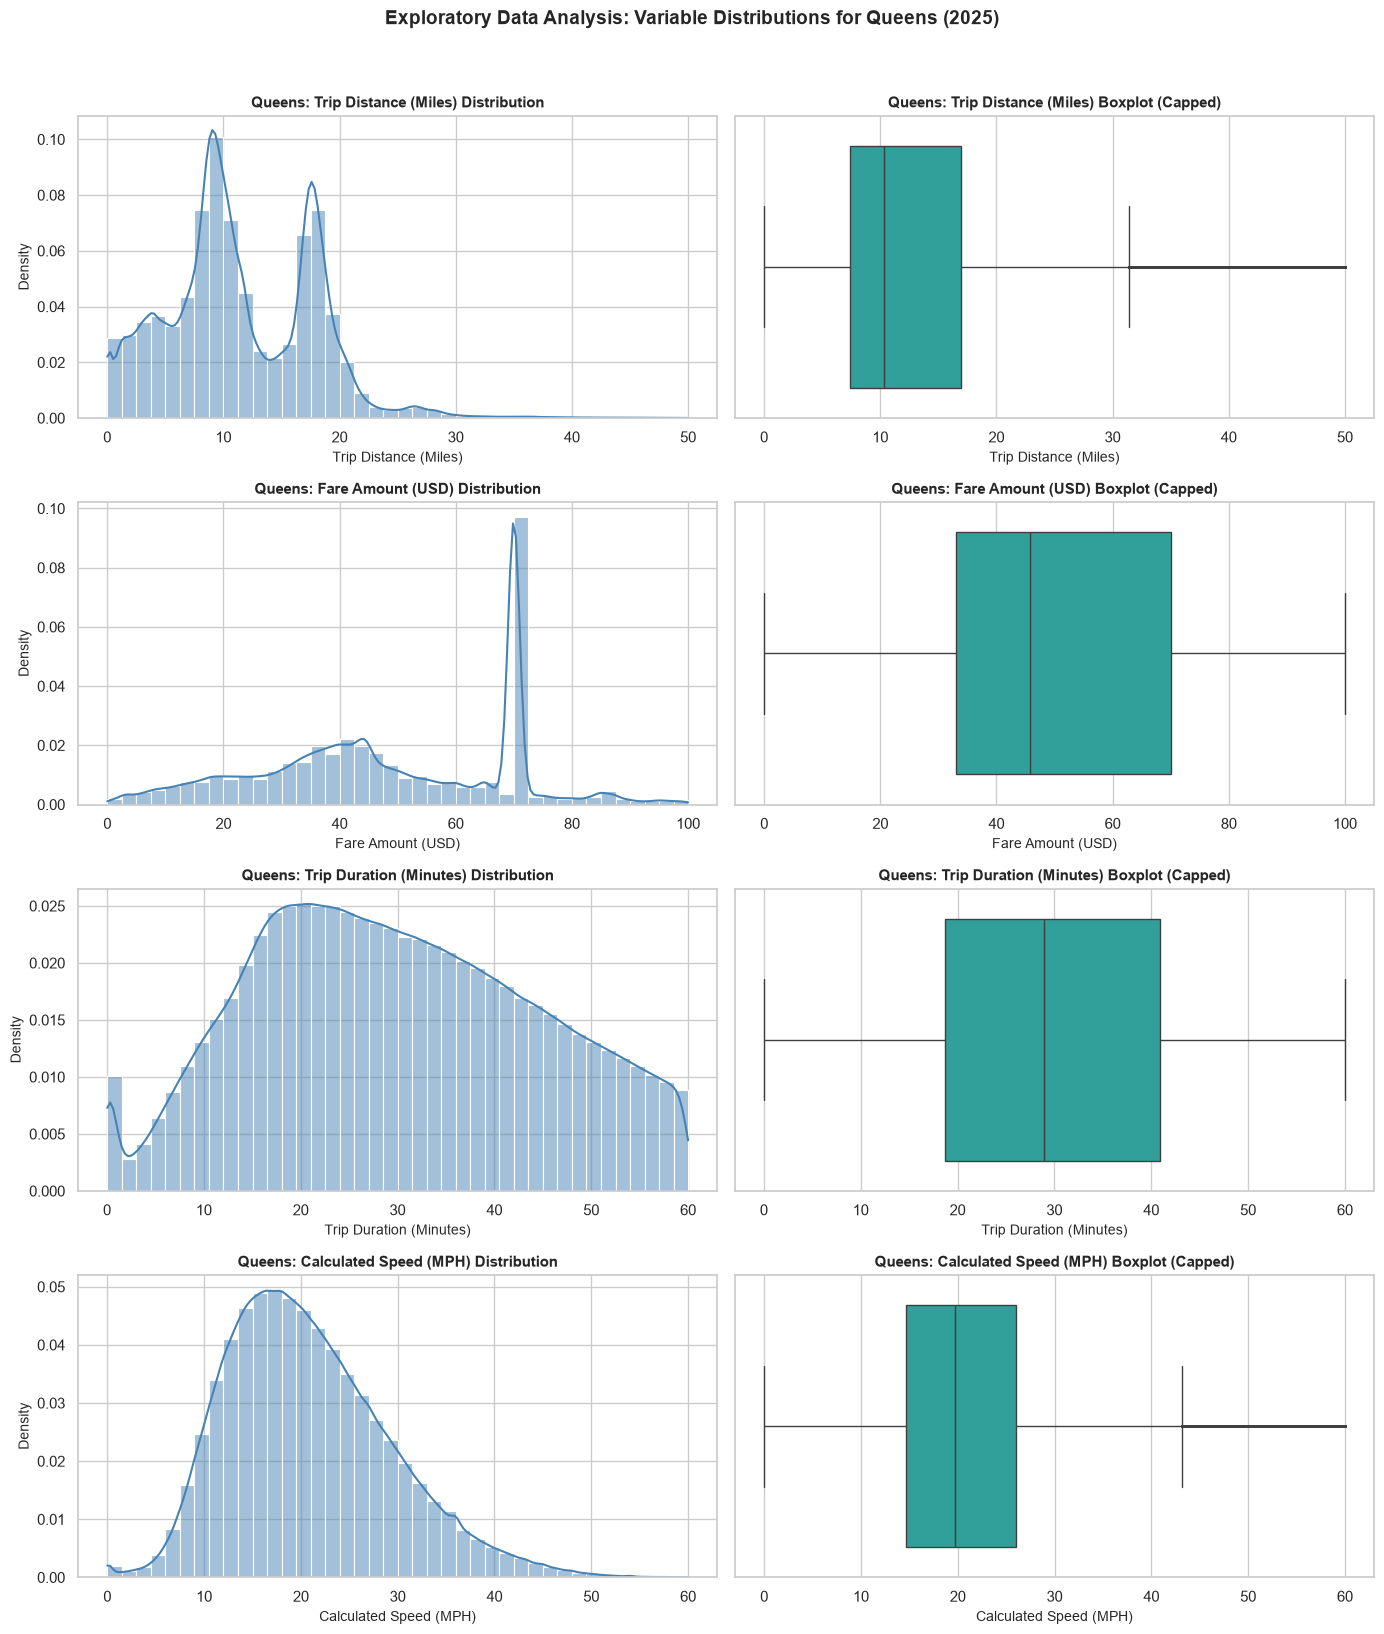

In [18]:
print("Processing borough: Queens...")
df_b = analyze_borough_stats('Queens')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('Queens', sample_percentage=100)

Processing borough: Brooklyn...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

 Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
Brooklyn       Pickup      1471290           5.57          4.42         2.53             4.29         7.33      26.85     15.50    16.87        24.39    34.91          27.36         19.07        15.15            22.80        33.55       12.53       6.43      8.48         11.11     15.02
Brooklyn      Dropoff      2455952           7.27          5.27         3.37             5.91        10.05      34.07     19.43    20.43        30.24    43.96          29.89         17.73        17.83            26.26        37.64       14.70       7.50      9.71         12.89     17.95
Fetching a 100% random sample for Brooklyn...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 1,471,290 sampled rows. Generating plots...
Saved distribution plots for Brooklyn to '../reports/figures/brooklyn_variables_distribution.png'!


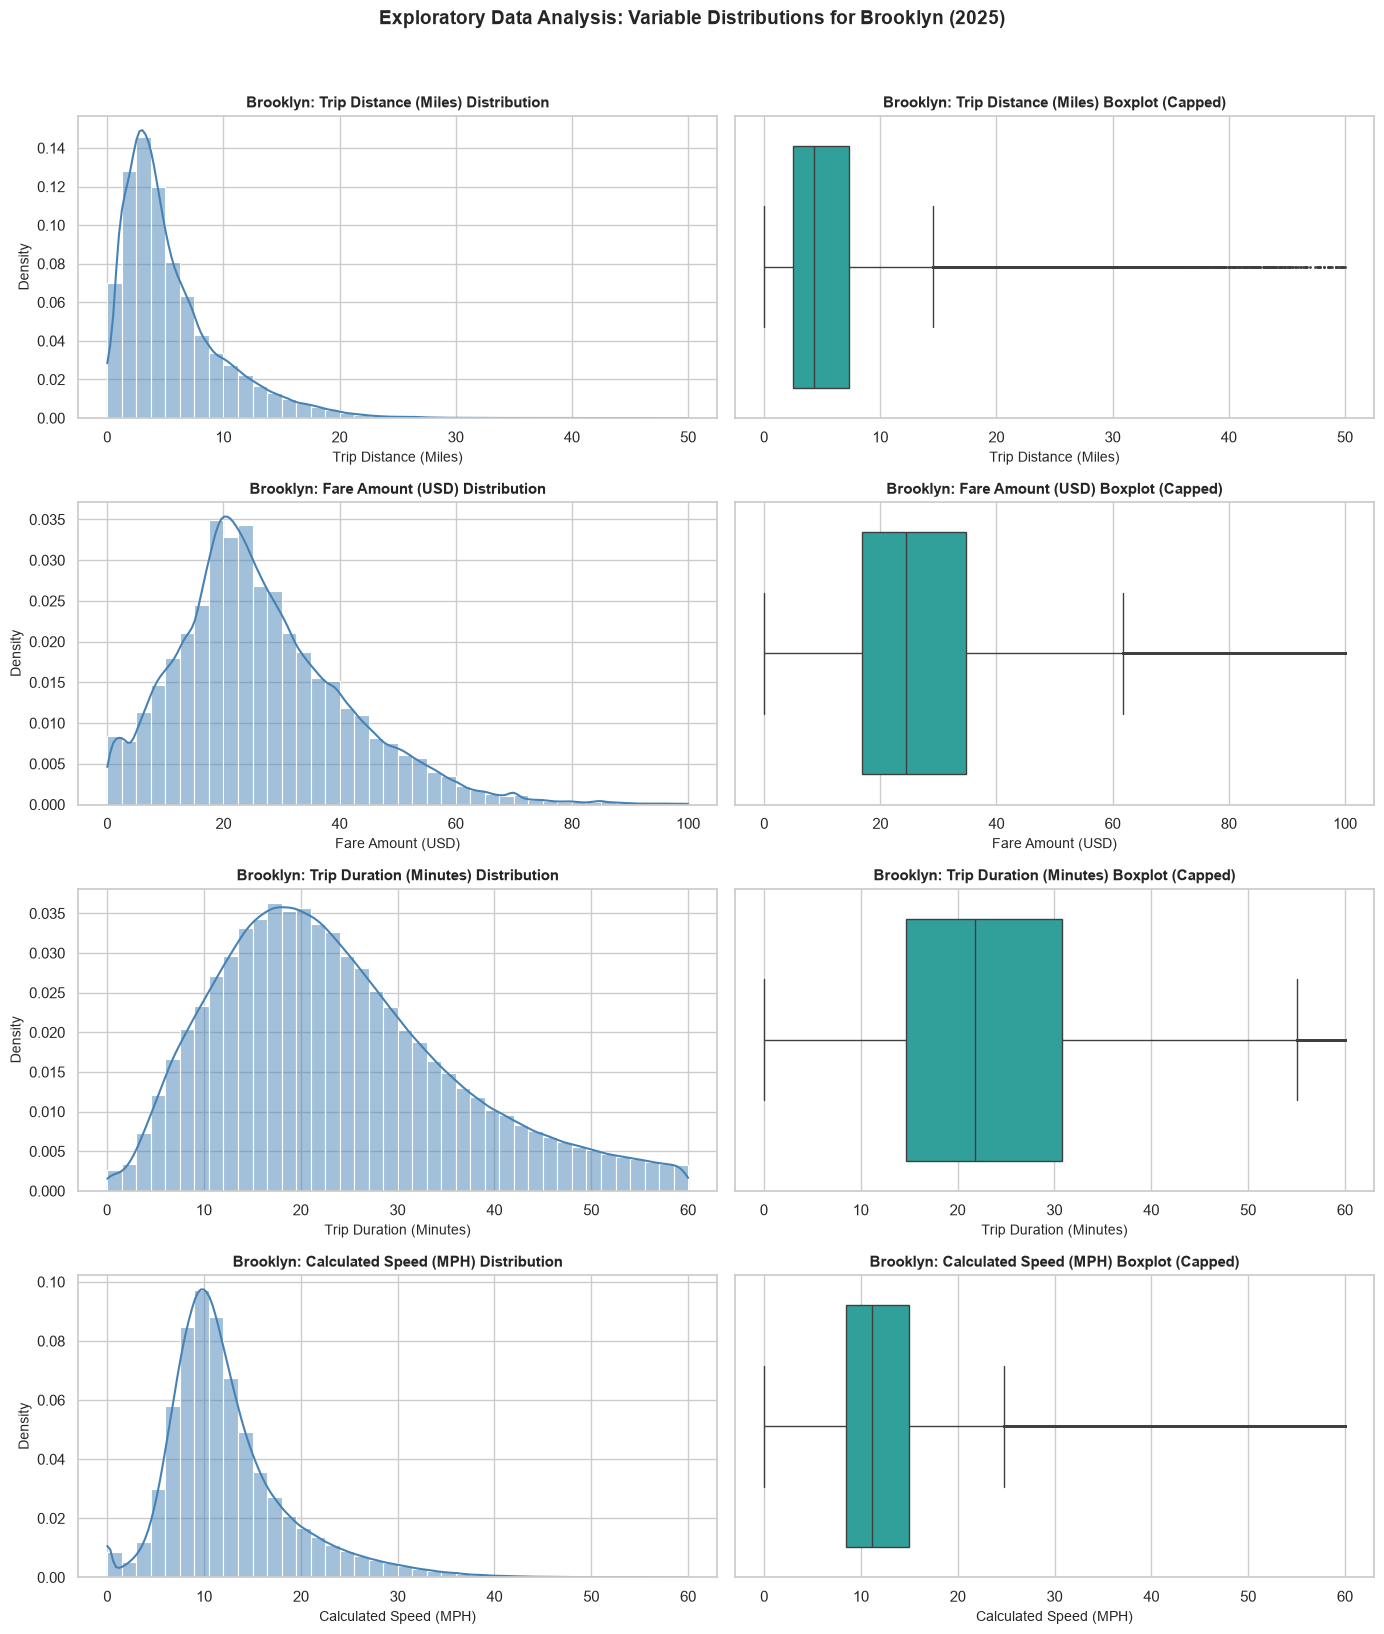

In [19]:
print("Processing borough: Brooklyn...")
df_b = analyze_borough_stats('Brooklyn')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('Brooklyn', sample_percentage=100)

Processing borough: Bronx...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
  Bronx       Pickup       339103           7.13          5.29         2.96             5.85        10.22      28.64     15.96    17.48        26.54    38.48          31.30         24.07        14.73            23.34        41.00       14.76       7.55      9.34         13.04     18.94
  Bronx      Dropoff       493819           9.02          5.91         4.25             8.30        12.47      35.79     20.47    21.20        33.19    46.40          31.45         21.37        17.37            25.93        38.98       18.29       8.98     11.05         17.21     24.46
Fetching a 100% random sample for Bronx...
Loaded 339,103 sampled rows. Generating plots...
Saved distribution plots for Bronx to '../repor

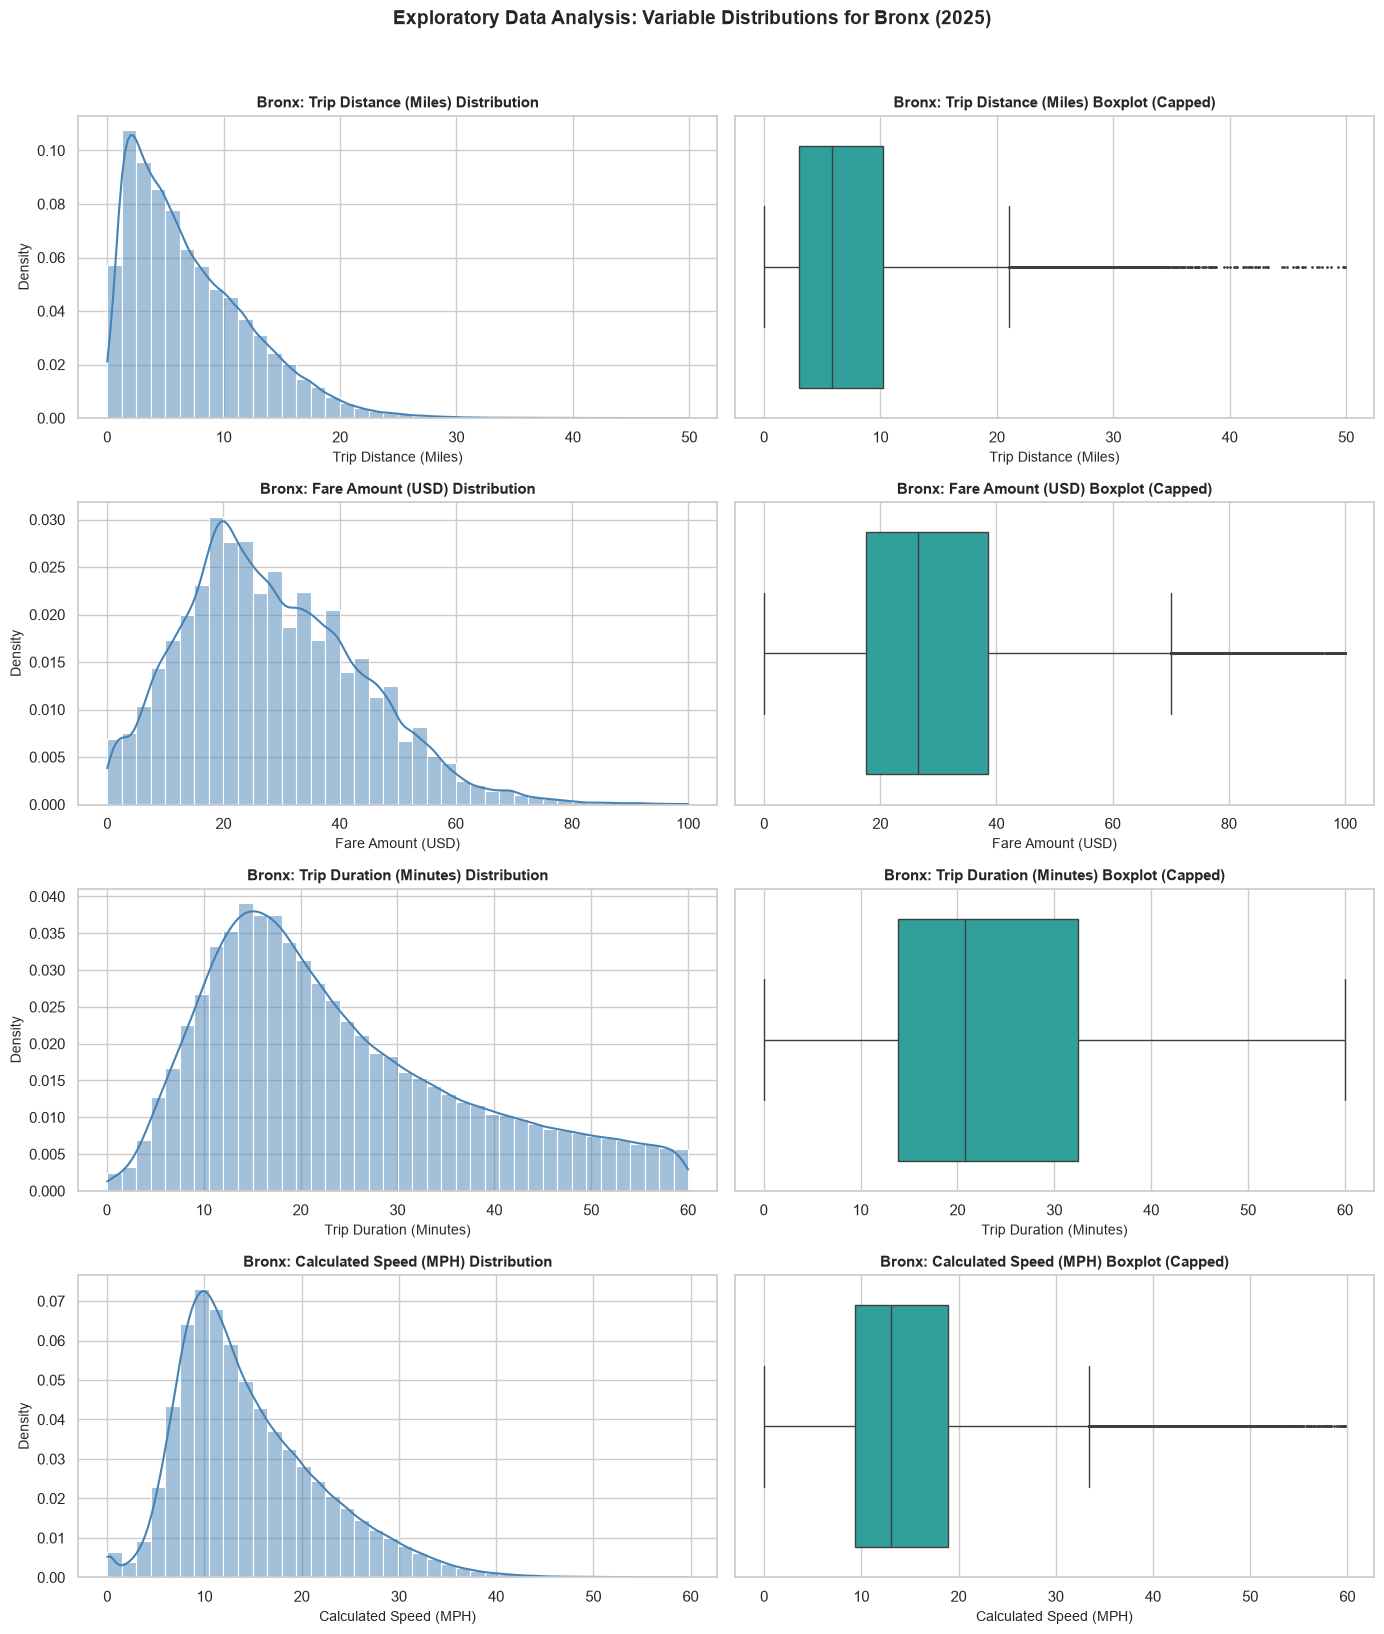

In [20]:
print("Processing borough: Bronx...")
df_b = analyze_borough_stats('Bronx')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('Bronx', sample_percentage=100)

Processing borough: Staten Island...
      Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
Staten Island       Pickup         3660           9.47          6.98         4.45             8.00        13.25      32.76     29.37    10.97        27.34    49.07          26.57         19.29        13.34            22.42        35.93       22.76       9.73     15.50         21.53     28.54
Staten Island      Dropoff        11518          19.52          8.38        14.74            20.58        25.56      74.87     36.56    54.37        80.88    98.39          44.38         21.93        32.28            42.72        55.15       27.76       8.97     21.75         27.36     33.67
Fetching a 100% random sample for Staten Island...
Loaded 3,660 sampled rows. Genera

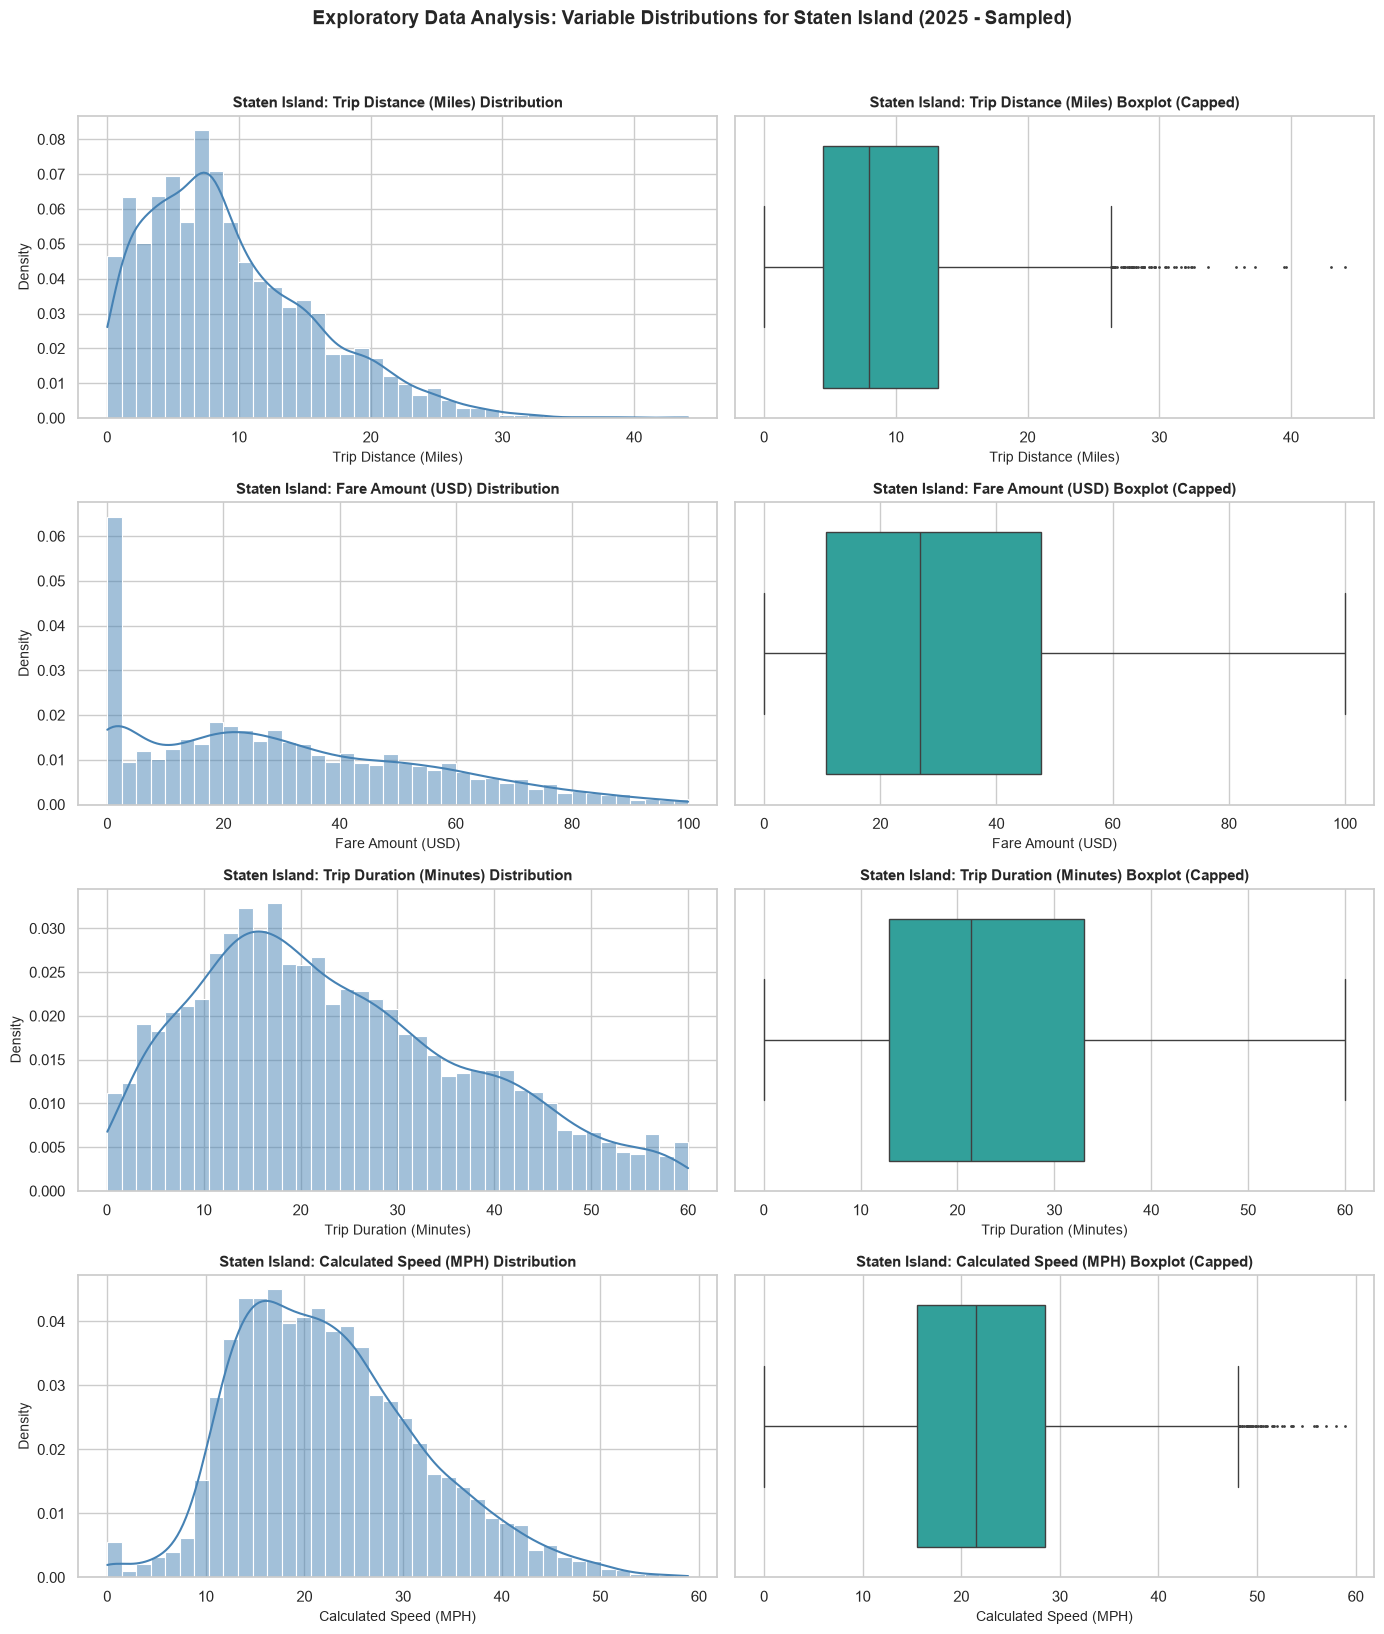

In [6]:
print("Processing borough: Staten Island...")
df_b = analyze_borough_stats('Staten Island')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('Staten Island', sample_percentage=100)

Processing borough: EWR...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Borough spatial_type  total_trips  mean_distance  std_distance  q1_distance  median_distance  q3_distance  mean_fare  std_fare  q1_fare  median_fare  q3_fare  mean_duration  std_duration  q1_duration  median_duration  q3_duration  mean_speed  std_speed  q1_speed  median_speed  q3_speed
    EWR       Pickup         1245           3.86          8.17         0.03             0.06         1.15      84.36     44.55    47.06        95.32   115.13           9.27         19.61         0.10             0.22         3.59       21.97      12.27     11.50         22.94     30.07
    EWR      Dropoff        84257          17.85          4.90        16.00            17.59        19.45      97.56     20.95    85.82        93.40   103.53          41.52         16.63        30.96            37.65        48.23       28.04       8.63     22.34         28.52     34.09
Fetching a 100% random sample for EWR...
Loaded 1,245 sampled rows. Generating plots...
Saved distribution plots for EWR to '../reports/fig

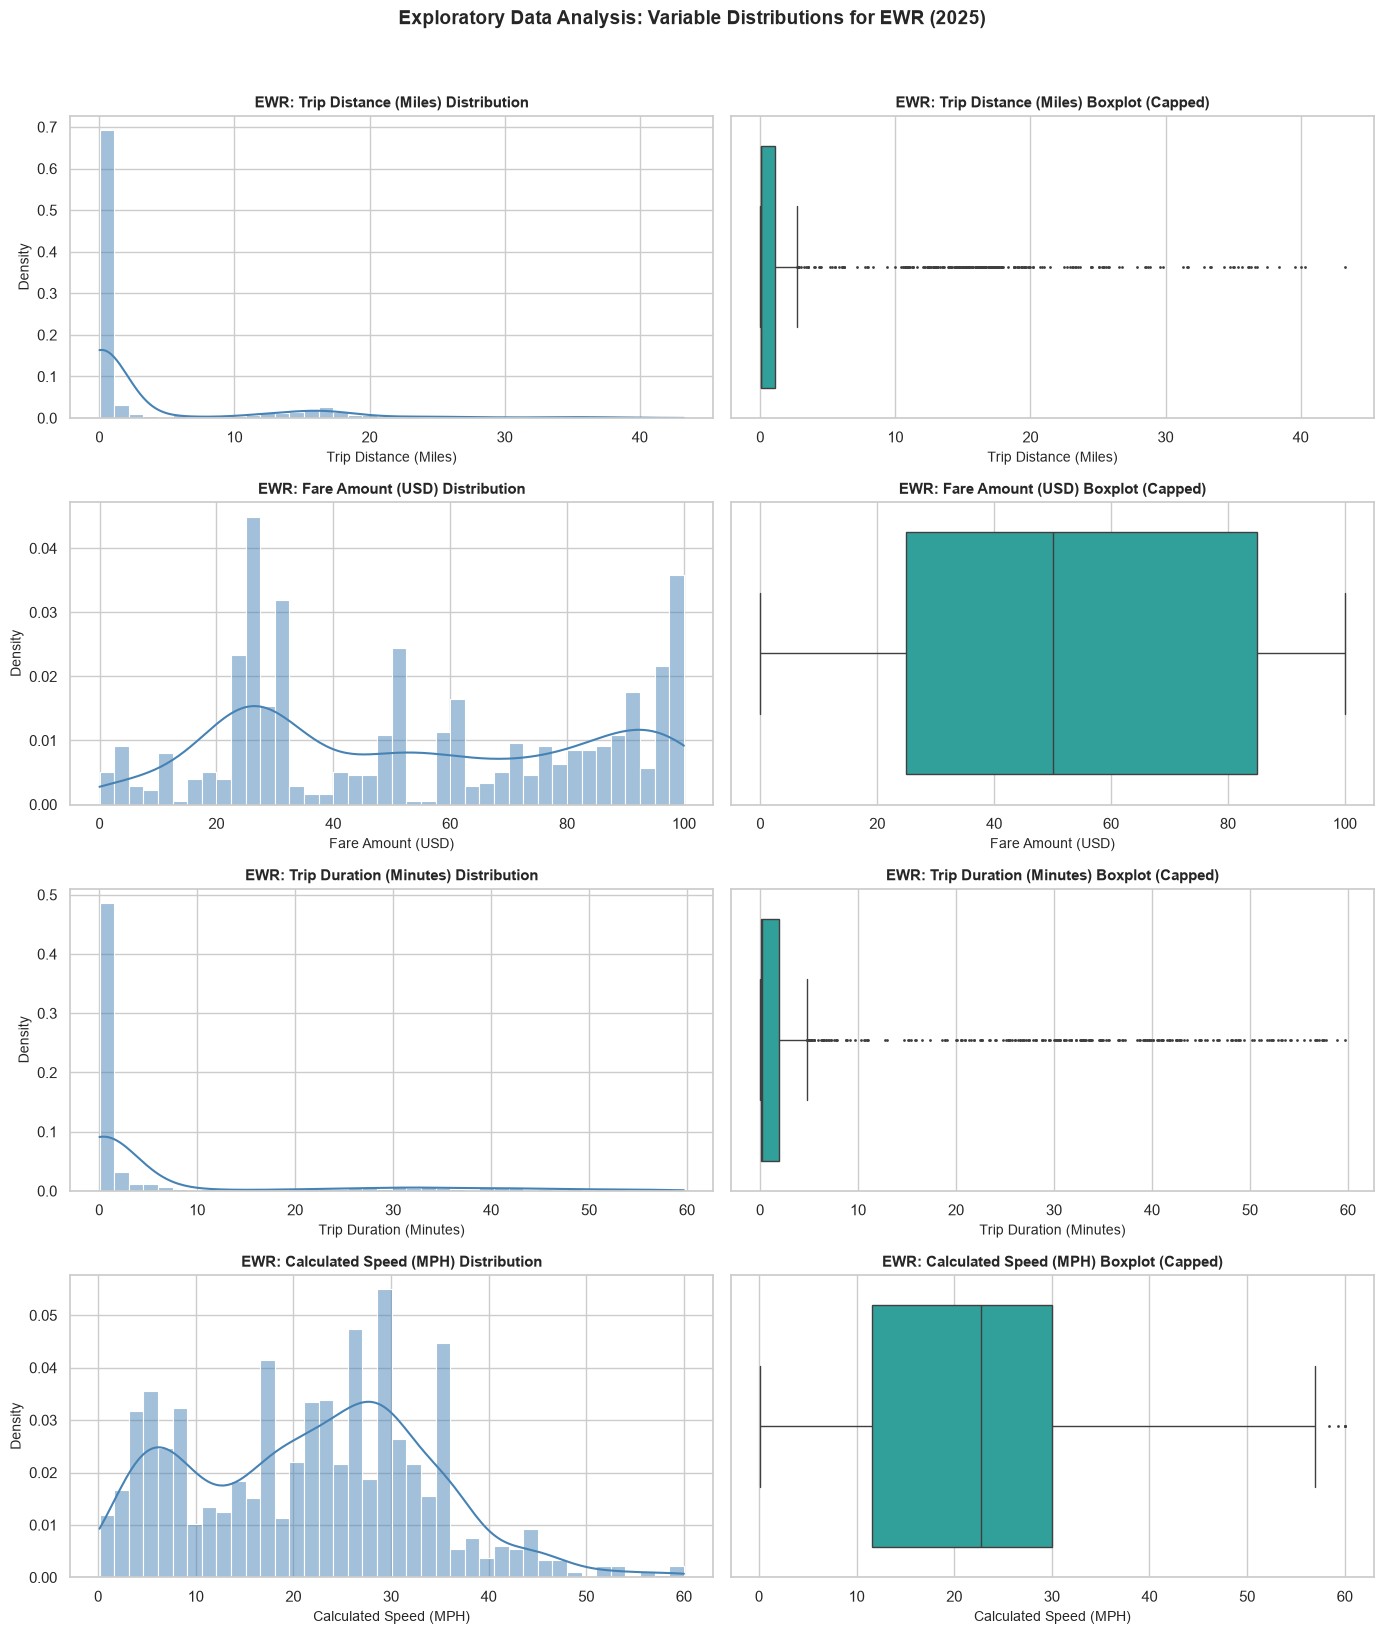

In [21]:
print("Processing borough: EWR...")
df_b = analyze_borough_stats('EWR')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_b.to_string(index=False))
plot_borough_distributions_sampled('EWR', sample_percentage=100)